# Homework 6: Decision Trees and Ensemble Learning

## Dataset
In this homework, we continue using the fuel efficiency dataset. Download it from here.

You can do it with wget:

```wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv```

The goal of this homework is to create a regression model for predicting the car fuel efficiency (column ```'fuel_efficiency_mpg'```).

In [ ]:
import os
import pandas as pd

filename = "car_fuel_efficiency_2026.csv"
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

if not os.path.exists(filename):
    !wget {url} -O {filename}

df = pd.read_csv(filename)
df.head()

## Preparing the dataset
- Fill missing values with zeros.
- Do the split with these exact calls:

```
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

- Use ```DictVectorizer(sparse=True)``` to turn the dataframes into matrices.

In [1]:
# Get the data
import os
import pandas as pd

filename = "car_fuel_efficiency_2026.csv"
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

if not os.path.exists(filename):
    !wget {url} -O {filename}

df = pd.read_csv(filename)
df.head()

--2026-10-30 10:12:36--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.004s  

2026-10-30 10:12:36 (156 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [2]:
# --- Prepare the dataset ---
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

# Check for missing values, then fill them with zeros
print(df.isnull().sum())
df = df.fillna(0)

# Split with the exact calls from the instructions above
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Separate the target and remove it from the features
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# One-hot encode with DictVectorizer (sparse=True, as per the instructions)
dv = DictVectorizer(sparse=True)

train_dicts = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

print(X_train.shape, X_val.shape)
print(dv.get_feature_names_out())

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64
(6000, 16) (2000, 16)
['acceleration' 'drivetrain=All-wheel drive'
 'drivetrain=Front-wheel drive' 'drivetrain=Rear-wheel drive'
 'engine_displacement' 'fuel_type=Diesel' 'fuel_type=Gasoline'
 'fuel_type=Hybrid' 'horsepower' 'model_year' 'num_cylinders' 'num_doors'
 'origin=Asia' 'origin=Europe' 'origin=USA' 'vehicle_weight']


## Question 1
Let's train a decision tree regressor to predict the ```fuel_efficiency_mpg``` variable.

- Train a model with ```max_depth=1```.

Which original feature is used for splitting the data? If you use ```DictVectorizer```, map a one-hot feature such as ```origin=USA``` back to its original column name.

- ```'vehicle_weight'```
- ```'model_year'```
- ```'origin'```
- ```'fuel_type'```

In [3]:
from sklearn.tree import DecisionTreeRegressor, export_text

# Train a tree with only one split
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

# Show the tree as text
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

# Pull out the feature used for the split, and map it back to the original column
feature = dv.get_feature_names_out()[dt.tree_.feature[0]]
original = feature.split('=')[0]

print('Split feature:', feature)
print('Answer:', original)

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

Split feature: model_year
Answer: model_year


## Question 2
Train a random forest regressor with these parameters:

- ```n_estimators=10```
- ```random_state=1```
- ```n_jobs=-1``` (optional - to make training faster)

What's the RMSE of this model on the validation data?

- 0.1837
- 1.837
- 18.37
- 183.7

In [4]:
from sklearn.ensemble import RandomForestRegressor

# RMSE function (same as Module 2)
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

# Train a random forest of 10 trees
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

# Predict on validation and score
y_pred = rf.predict(X_val)
score = rmse(y_val, y_pred)

print(f'RMSE: {score:.4f}')

RMSE: 1.8332


## Question 3
Now let's experiment with the ```n_estimators``` parameter

- Try these values of this parameter: ```[10, 50, 100, 150]```.
- Set ```random_state``` to ```1```.
- Evaluate the model on the validation dataset.

Which value gives the lowest validation RMSE? Consider 3 decimal places for calculating the answer.

- 10
- 50
- 100
- 150

In [5]:
scores = {}

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    score = round(rmse(y_val, y_pred), 3)

    scores[n] = score
    print(n, score)

best_n = min(scores, key=scores.get)
print('Answer:', best_n)

10 1.833
50 1.774
100 1.77
150 1.769
Answer: 150


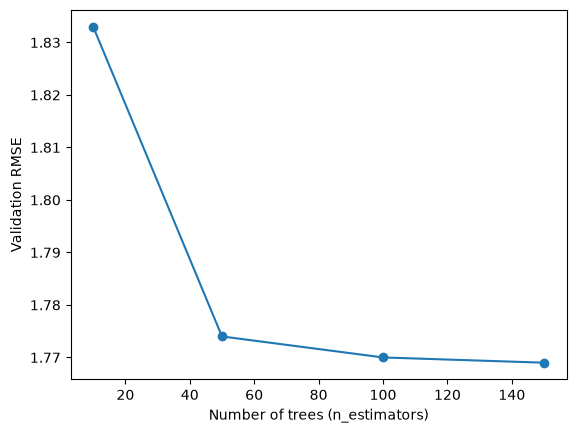

In [6]:
import matplotlib.pyplot as plt

plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.xlabel('Number of trees (n_estimators)')
plt.ylabel('Validation RMSE')
plt.show()

## Question 4
Let's select the best ```max_depth```:

- Try different values of ```max_depth```: ```[10, 15, 20, 25]```
- For each of these values,
    - try different values of ```n_estimators``` from ```[10, 50, 100, 150]```
    - calculate the mean RMSE
- Fix the random seed: ```random_state=1```

What's the best ```max_depth```, using the mean RMSE?

- 10
- 15
- 20
- 25

In [7]:
mean_scores = {}

for depth in [10, 15, 20, 25]:
    scores = []

    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth,
                                   random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        scores.append(rmse(y_val, y_pred))

    mean_scores[depth] = np.mean(scores)
    print(f'max_depth={depth}: mean RMSE = {mean_scores[depth]:.3f}')

best_depth = min(mean_scores, key=mean_scores.get)
print('Answer:', best_depth)

max_depth=10: mean RMSE = 1.754
max_depth=15: mean RMSE = 1.784
max_depth=20: mean RMSE = 1.787
max_depth=25: mean RMSE = 1.786
Answer: 10


## Question 5
We can extract feature importance information from tree-based models.

At each step of the decision tree learning algorithm, it finds the best split. When doing it, we can calculate "gain" - the reduction in impurity before and after the split. This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the ```feature_importances_``` field.

For this homework question, we'll find the most important feature:

- Train the model with these parameters:
    - ```n_estimators=10```,
    - ```max_depth=20```,
    - ```random_state=1```,
    - ```n_jobs=-1``` (optional)
- Get the feature importance information from this model

What's the most important feature (among these 4)?

- ```vehicle_weight```
- ```horsepower```
- ```acceleration```
- ```engine_displacement```

In [8]:
# Train the forest with the question's settings
rf = RandomForestRegressor(n_estimators=10, max_depth=20,
                           random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

# Match each importance score to its column name, highest first
importances = pd.Series(rf.feature_importances_,
                        index=dv.get_feature_names_out())
importances = importances.sort_values(ascending=False)
print(importances.round(3))

# Only the four features in the answer options
options = ['vehicle_weight', 'horsepower', 'acceleration', 'engine_displacement']
print('Answer:', importances[options].idxmax())

model_year                      0.296
vehicle_weight                  0.203
fuel_type=Gasoline              0.161
horsepower                      0.078
engine_displacement             0.061
acceleration                    0.055
origin=USA                      0.042
drivetrain=Front-wheel drive    0.020
num_doors                       0.019
fuel_type=Diesel                0.017
fuel_type=Hybrid                0.016
drivetrain=All-wheel drive      0.008
num_cylinders                   0.007
origin=Asia                     0.007
drivetrain=Rear-wheel drive     0.006
origin=Europe                   0.003
dtype: float64
Answer: vehicle_weight


## Question 6
Now let's train an XGBoost model! For this question, we'll tune the ```eta``` parameter:

- Install XGBoost
- Create DMatrix for train and validation
- Create a watchlist
- Train a model with these parameters for 100 rounds:

```
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'reg:squarederror',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}
```

Now change ```eta``` from ```0.3``` to ```0.1```.

Which eta leads to the best RMSE score on the validation dataset?

- 0.3
- 0.1
- Both give equal value

In [9]:
%pip install -q xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import xgboost as xgb

# Wrap the data in XGBoost's format (from the lecture)
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

# Watchlist: report the score on both sets as training goes on (from the lecture)
watchlist = [(dtrain, 'train'), (dval, 'val')]

scores = {}

for eta in [0.3, 0.1]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }

    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                      evals=watchlist, evals_result=evals_result,
                      verbose_eval=False)

    val_rmse = evals_result['val']['rmse'][-1]   # validation RMSE after the 100th round
    scores[eta] = round(val_rmse, 3)
    print(f'eta={eta}: validation RMSE = {val_rmse:.3f}')

if scores[0.3] == scores[0.1]:
    print('Answer: Both give equal value')
else:
    print('Answer:', min(scores, key=scores.get))

eta=0.3: validation RMSE = 1.826
eta=0.1: validation RMSE = 1.725
Answer: 0.1


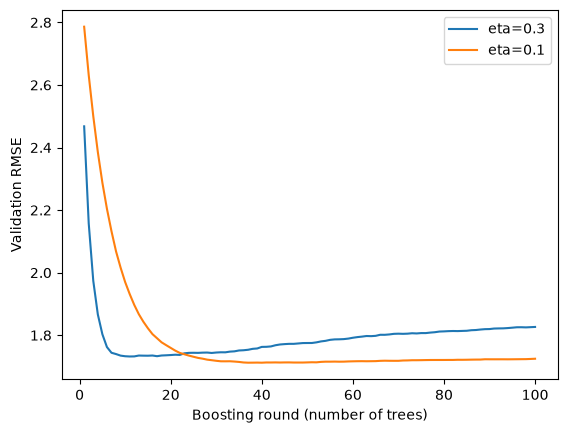

In [11]:
import matplotlib.pyplot as plt

curves = {}

for eta in [0.3, 0.1]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }

    evals_result = {}
    xgb.train(xgb_params, dtrain, num_boost_round=100,
              evals=watchlist, evals_result=evals_result,
              verbose_eval=False)

    curves[eta] = evals_result['val']['rmse']   # all 100 rounds, not just the last

for eta, val_rmse in curves.items():
    plt.plot(range(1, 101), val_rmse, label=f'eta={eta}')

plt.xlabel('Boosting round (number of trees)')
plt.ylabel('Validation RMSE')
plt.legend()
plt.show()

## Submit the results
- Submit your results here: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw06
- The numerical options are calculated from the pinned 2026 release. If your answer doesn't match any option exactly, select the closest one. If it's exactly in between two options, select the higher value.
- Share what you learned in a short post using ```#mlzoomcamp``` and submit the post link with your homework.